> **Credit:** This project is inspired by the free lesson
> [*Building a KPI Dashboard with Pandas*](https://www.mathewkanalytics.com/lessons/mastering-pandas/058-building-a-kpi-dashboard-with-pandas/)
> by **[Mathew K Analytics](https://www.mathewkanalytics.com/)**
> ([YouTube video](https://www.youtube.com/watch?v=lid1q679cs0)).
> The original uses the Titanic dataset; this version applies the same workflow to a retail sales dataset and extends it.

# 📊 Retail Sales KPI Dashboard with Pandas

**Goal:** Turn 8,399 raw order lines from a retail store ("Superstore", Canada, 2009–2012) into a one-page KPI dashboard
that a manager could read in 30 seconds.

**What is a KPI?** A *Key Performance Indicator* is a single number that tells you whether the business is doing well
(e.g. total sales, profit margin, average order value). A dashboard puts the most important KPIs in one place.

### The workflow (same steps the original lesson teaches)
1. **Load** the data
2. **Explore** it - what columns, types, sizes?
3. **Clean** it - fix types, fill missing values
4. **Create KPI columns** - new columns derived from existing ones
5. **Aggregate** - headline KPIs and KPIs per group
6. **Time-based KPIs** - how do things change month to month?
7. **Visualize** - build the dashboard image
8. **Make it reusable** - a function that builds a KPI report for any filter
9. **Write insights** - what does the data actually say?



## Step 0 - Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)  # nicer number printing

def check(name, value, expected, tol=0.01):
    """Tiny helper that tells you if your answer is right."""
    try:
        value = float(value)
        ok = abs(value - expected) <= tol * max(1, abs(expected))
        shown = f"{value:,.4g}"
    except (TypeError, ValueError):  # e.g. you still have ... in your code
        ok, shown = False, repr(value)
    print(("✅ " if ok else "❌ ") + f"{name}: got {shown}" + ("" if ok else f" (expected about {expected:,.4g})"))

## Step 1 - Load the data

The CSV is stored in `data/`. If it's missing, we download it from the source.

**Lesson:** Not every file is UTF-8. This one contains characters like `¨` encoded as *latin-1*,
so `pd.read_csv` fails without `encoding="latin-1"`. Try removing it and see the error!

In [2]:
from pathlib import Path

DATA_URL = "https://raw.githubusercontent.com/curran/data/gh-pages/superstoreSales/superstoreSales.csv"
ROOT = Path("..") if Path("../data").exists() else Path(".")  # project folder
DATA_PATH = ROOT / "data" / "superstore_sales.csv"

source = DATA_PATH if DATA_PATH.exists() else DATA_URL
raw = pd.read_csv(source, encoding="latin-1")
df = raw.copy()  # keep the raw data untouched, work on a copy
print("Loaded from:", source)

Loaded from: ../data/superstore_sales.csv


## Step 2 - Explore

Before calculating anything, look at the data. Answer for yourself: how many rows? Which columns are numbers,
which are text, which should be dates?

Print the shape of `df`, show the first 5 rows, and show `df.info()`.

In [3]:
# How many rows and columns?
print(df.shape)

# First 5 rows
df.head()

(8399, 21)


,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,...,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3,10/13/2010,Low,6,261.54,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293,10/1/2012,High,49,"10,123.02",0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293,10/1/2012,High,27,244.57,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-DÂ¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012
3,80,483,7/10/2011,High,30,"4,965.76",0.08,Regular Air,"1,198.97",195.99,...,Clay Rozendal,Nunavut,Nunavut,Corporate,Technology,Telephones and Communication,R380,Small Box,0.58,7/12/2011
4,85,515,8/28/2010,Not Specified,19,394.27,0.08,Regular Air,30.94,21.78,...,Carlos Soltero,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,Holmes HEPA Air Purifier,Medium Box,0.50,8/30/2010


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row ID                8399 non-null   int64  
 1   Order ID              8399 non-null   int64  
 2   Order Date            8399 non-null   object 
 3   Order Priority        8399 non-null   object 
 4   Order Quantity        8399 non-null   int64  
 5   Sales                 8399 non-null   float64
 6   Discount              8399 non-null   float64
 7   Ship Mode             8399 non-null   object 
 8   Profit                8399 non-null   float64
 9   Unit Price            8399 non-null   float64
 10  Shipping Cost         8399 non-null   float64
 11  Customer Name         8399 non-null   object 
 12  Province              8399 non-null   object 
 13  Region                8399 non-null   object 
 14  Customer Segment      8399 non-null   object 
 15  Product Category     

**Notice:**
- `Order Date` and `Ship Date` are `object` (text), not dates → we must convert them.
- `Product Base Margin` has fewer non-null values than the other columns → missing values.
- One row is one **order line** (one product in an order). One order can have several lines - so
  "number of orders" is **not** the number of rows!

In [5]:
df.describe()

,Row ID,Order ID,Order Quantity,Sales,Discount,Profit,Unit Price,Shipping Cost,Product Base Margin
count,"8,399.00","8,399.00","8,399.00","8,399.00","8,399.00","8,399.00","8,399.00","8,399.00","8,336.00"
mean,"4,200.00","29,965.18",25.57,"1,775.88",0.05,181.18,89.35,12.84,0.51
std,"2,424.73","17,260.88",14.48,"3,585.05",0.03,"1,196.65",290.35,17.26,0.14
min,1.00,3.00,1.00,2.24,0.00,"-14,140.70",0.99,0.49,0.35
25%,"2,100.50","15,011.50",13.00,143.19,0.02,-83.31,6.48,3.30,0.38
50%,"4,200.00","29,857.00",26.00,449.42,0.05,-1.50,20.99,6.07,0.52
75%,"6,299.50","44,596.00",38.00,"1,709.32",0.08,162.75,85.99,13.99,0.59
max,"8,399.00","59,973.00",50.00,"89,061.05",0.25,"27,220.69","6,783.02",164.73,0.85


## Step 3 - Clean

### 3a. Missing values
Count the missing values in every column.

In [6]:
missing = df.isnull().sum()
missing[missing > 0]

Product Base Margin    63
dtype: int64

Only `Product Base Margin` has gaps. The Titanic lesson filled missing ages with the **overall median**.
We can do better: margins differ a lot between product types, so we fill each gap with the median
**of its own Product Sub-Category**. `groupby(...).transform("median")` returns a value for every row, aligned to `df`.

In [7]:
group_median = df.groupby("Product Sub-Category")["Product Base Margin"].transform("median")
df["Product Base Margin"] = df["Product Base Margin"].fillna(group_median)
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### 3b. Fix data types
Convert `Order Date` and `Ship Date` to real dates with `pd.to_datetime`.
The format is month/day/year, e.g. `10/13/2010`.

In [8]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

In [9]:
check("Order Date is datetime", int(pd.api.types.is_datetime64_any_dtype(df["Order Date"])), 1)
check("First order date year", df["Order Date"].min().year, 2009)

✅ Order Date is datetime: got 1
✅ First order date year: got 2,009


Text columns with few distinct values are *categories*. Converting them saves memory and makes intent clear (same as the original lesson):

In [10]:
for col in ["Order Priority", "Ship Mode", "Region", "Customer Segment", "Product Category"]:
    df[col] = df[col].astype("category")
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Step 4 - Create KPI columns

Good KPIs often need columns that don't exist yet. We'll derive them from existing columns.

Create these four columns:
| Column | Meaning |
|---|---|
| `Days to Ship` | number of days between `Order Date` and `Ship Date` |
| `Is Loss` | `True` if `Profit` is below 0 |
| `Year` | year of the order |
| `Month` | first day of the order's month (for monthly trends) - given |

In [11]:
df["Days to Ship"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Is Loss"] = df["Profit"] < 0
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()

In [12]:
check("Average days to ship", df["Days to Ship"].mean(), 2.033)
check("Share of loss-making order lines", df["Is Loss"].mean(), 0.5077)
check("Number of distinct years", df["Year"].nunique(), 4)

✅ Average days to ship: got 2.033
✅ Share of loss-making order lines: got 0.5077
✅ Number of distinct years: got 4


## Step 5 - Headline KPIs

These are the big numbers at the top of any dashboard.

Calculate:
- `total_sales` - sum of `Sales`
- `total_profit` - sum of `Profit`
- `profit_margin` - profit as a share of sales
- `n_orders` - number of **unique** orders (remember: rows ≠ orders!)
- `n_customers` - number of unique customers
- `avg_order_value` - sales per order

In [13]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_sales
n_orders = df["Order ID"].nunique()
n_customers = df["Customer Name"].nunique()
avg_order_value = total_sales / n_orders

In [14]:
check("Total sales", total_sales, 14_915_600.82)
check("Total profit", total_profit, 1_521_767.98)
check("Profit margin", profit_margin, 0.1020)
check("Orders", n_orders, 5496)
check("Customers", n_customers, 795)
check("Average order value", avg_order_value, 2713.90)

✅ Total sales: got 1.492e+07
✅ Total profit: got 1.522e+06
✅ Profit margin: got 0.102
✅ Orders: got 5,496
✅ Customers: got 795
✅ Average order value: got 2,714


Put them in one small table - this is the *KPI summary* from the original mini-project, but formatted for humans:

In [15]:
kpi_summary_table = pd.DataFrame({
    "KPI": ["Total Sales", "Total Profit", "Profit Margin", "Orders", "Customers", "Avg Order Value"],
    "Value": [f"${total_sales:,.0f}", f"${total_profit:,.0f}", f"{profit_margin:.1%}",
              f"{n_orders:,}", f"{n_customers:,}", f"${avg_order_value:,.0f}"],
})
kpi_summary_table

,KPI,Value
0,Total Sales,"$14,915,601"
1,Total Profit,"$1,521,768"
2,Profit Margin,10.2%
3,Orders,"5,496"
4,Customers,795
5,Avg Order Value,"$2,714"


## Step 6 - KPIs by group

Totals hide the story. Break them down with `groupby` + `agg`.

Build `by_category`: one row per `Product Category` with columns `Sales` (sum), `Profit` (sum)
and `Orders` (number of unique orders). Then add a `Margin` column = Profit / Sales.

In [16]:
by_category = df.groupby("Product Category", observed=True).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
)
by_category["Margin"] = by_category["Profit"] / by_category["Sales"]
by_category.sort_values("Sales", ascending=False)

,Sales,Profit,Orders,Margin
Product Category,,,,
Technology,"5,984,248.18","886,313.52",1858,0.15
Furniture,"5,178,590.54","117,433.03",1561,0.02
Office Supplies,"3,752,762.10","518,021.43",3632,0.14


In [17]:
check("Furniture margin", by_category.loc["Furniture", "Margin"], 0.0227)
check("Technology profit", by_category.loc["Technology", "Profit"], 886_313.52)

✅ Furniture margin: got 0.02268
✅ Technology profit: got 8.863e+05


🤔 **Think:** Furniture sells almost as much as Technology. Compare their margins. What would you tell the manager?

Total `Sales` per `Region`, sorted from highest to lowest.

In [18]:
sales_by_region = df.groupby("Region", observed=True)["Sales"].sum().sort_values(ascending=False)
sales_by_region

Region
West                    3,597,549.28
Ontario                 3,063,212.48
Prarie                  2,837,304.60
Atlantic                2,014,248.20
Quebec                  1,510,195.08
Yukon                     975,867.37
Northwest Territories     800,847.33
Nunavut                   116,376.48
Name: Sales, dtype: float64

In [19]:
check("Top region sales (West)", sales_by_region.iloc[0], 3_597_549.27)

✅ Top region sales (West): got 3.598e+06


### Two-dimensional KPIs: pivot tables
Like the original's *class × sex* survival matrix, a pivot table shows a KPI across two dimensions at once.

Make a pivot table of total `Profit` with `Product Category` as rows and `Customer Segment` as columns.

In [20]:
profit_pivot = df.pivot_table(values="Profit", index="Product Category",
                              columns="Customer Segment", aggfunc="sum", observed=True)
profit_pivot

Customer Segment,Consumer,Corporate,Home Office,Small Business
Product Category,,,,
Furniture,"42,728.26","22,008.08","23,979.20","28,717.49"
Office Supplies,"88,532.29","203,037.38","121,145.65","105,306.11"
Technology,"156,699.39","374,700.54","173,229.18","181,684.41"


In [21]:
check("Corporate × Technology profit", profit_pivot.loc["Technology", "Corporate"], 374_701)

✅ Corporate × Technology profit: got 3.747e+05


### Operational KPI: shipping speed
Does paying attention to priority actually make orders ship faster?

In [22]:
df.groupby("Order Priority", observed=True)["Days to Ship"].mean().sort_values()

Order Priority
High            1.41
Not Specified   1.47
Medium          1.47
Critical        1.52
Low             4.24
Name: Days to Ship, dtype: float64

## Step 7 - Time-based KPIs

The Titanic data had no dates, so the original lesson *faked* time using ticket letters.
Our data has real order dates - so we can do proper trends.

1. `monthly_sales` - total `Sales` per `Month` (the column you created in Step 4)
2. `yearly_sales` - total `Sales` per `Year`
3. `yoy_growth` - year-over-year growth of `yearly_sales` (look up `.pct_change()`)

In [23]:
monthly_sales = df.groupby("Month")["Sales"].sum()
yearly_sales = df.groupby("Year")["Sales"].sum()
yoy_growth = yearly_sales.pct_change()
pd.DataFrame({"Sales": yearly_sales, "YoY growth": yoy_growth})

,Sales,YoY growth
Year,,
2009,"4,209,139.46",NaN
2010,"3,549,680.80",-0.16
2011,"3,436,816.70",-0.03
2012,"3,719,963.86",0.08


In [24]:
check("Number of months", len(monthly_sales), 48)
check("2012 growth vs 2011", yoy_growth.loc[2012], 0.0824)

✅ Number of months: got 48
✅ 2012 growth vs 2011: got 0.08239


Monthly numbers are noisy. A **3-month rolling average** smooths them so the trend is visible:

In [25]:
sales_trend = monthly_sales.rolling(3).mean()
sales_trend.tail()

Month
2012-08-01   274,045.25
2012-09-01   287,942.13
2012-10-01   324,087.81
2012-11-01   308,512.80
2012-12-01   320,658.72
Name: Sales, dtype: float64

## Step 8 - Visualize: the dashboard

The original lesson plotted one bar chart. A real dashboard combines **headline numbers** and a few **focused charts**
on one page. We use matplotlib's `subplot_mosaic` to lay out the panels.

Design choices worth learning:
- **Headline KPIs are big numbers, not charts** - a single value doesn't need an axis.
- **One color for one series.** Color only when it *means* something.
- **Horizontal bars** for category names - the labels stay readable.
- **Sorted bars** - the reader instantly sees the biggest and smallest.
- **Remove chart junk** - no top/right borders, light grid.

Read this cell slowly: every line is a design decision. Then change something and re-run it!

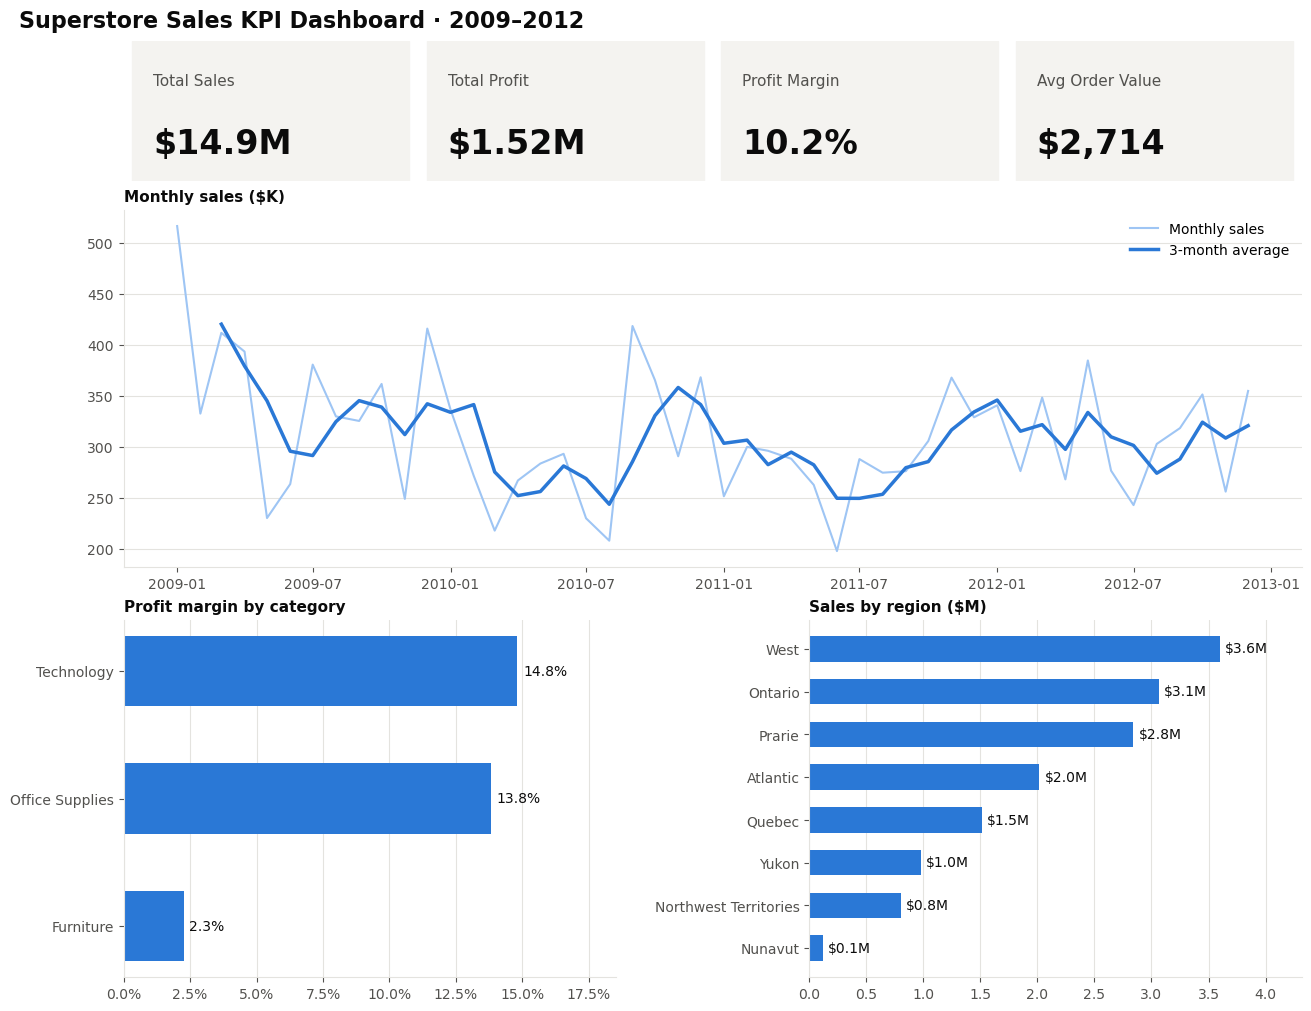

In [26]:
BLUE, BLUE_LIGHT, INK, MUTED, GRID = "#2a78d6", "#9ec5f4", "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titlecolor": INK,
})

fig, ax = plt.subplot_mosaic(
    [["cards", "cards"],
     ["trend", "trend"],
     ["margin", "region"]],
    figsize=(13, 10), height_ratios=[0.55, 1.4, 1.4], layout="constrained",
)
fig.patch.set_facecolor("white")
fig.suptitle("Superstore Sales KPI Dashboard · 2009–2012", x=0.01, ha="left",
             fontsize=16, fontweight="bold", color=INK)

# --- Row 1: headline KPI cards ---------------------------------------------
# One invisible axis, 4 units wide: card i lives between x=i and x=i+1.
cards = [("Total Sales", f"${total_sales/1e6:,.1f}M"),
         ("Total Profit", f"${total_profit/1e6:,.2f}M"),
         ("Profit Margin", f"{profit_margin:.1%}"),
         ("Avg Order Value", f"${avg_order_value:,.0f}")]
a = ax["cards"]
a.set_xlim(0, len(cards)); a.set_ylim(0, 1); a.set_axis_off()
for i, (label, value) in enumerate(cards):
    a.add_patch(plt.Rectangle((i + 0.03, 0), 0.94, 1, color="#f4f3f0"))
    a.text(i + 0.1, 0.68, label, fontsize=11, color=MUTED)
    a.text(i + 0.1, 0.2, value, fontsize=24, fontweight="bold", color=INK)

# --- Row 2: monthly sales trend ---------------------------------------------
a = ax["trend"]
a.plot(monthly_sales.index, monthly_sales / 1e3, color=BLUE_LIGHT, linewidth=1.5, label="Monthly sales")
a.plot(sales_trend.index, sales_trend / 1e3, color=BLUE, linewidth=2.5, label="3-month average")
a.set_title("Monthly sales ($K)")
a.legend(frameon=False, loc="upper right")

# --- Row 3 left: profit margin by category ----------------------------------
a = ax["margin"]
m = by_category["Margin"].sort_values()
bars = a.barh(m.index, m.values, color=BLUE, height=0.55)
a.bar_label(bars, labels=[f"{v:.1%}" for v in m.values], padding=4, color=INK)
a.set_title("Profit margin by category")
a.set_xlim(0, m.max() * 1.25)
a.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

# --- Row 3 right: sales by region -------------------------------------------
a = ax["region"]
r = sales_by_region.sort_values() / 1e6
bars = a.barh(r.index, r.values, color=BLUE, height=0.6)
a.bar_label(bars, labels=[f"${v:.1f}M" for v in r.values], padding=4, color=INK)
a.set_title("Sales by region ($M)")
a.set_xlim(0, r.max() * 1.2)

for key in ["trend", "margin", "region"]:
    ax[key].spines[["top", "right"]].set_visible(False)
    ax[key].grid(axis="x" if key != "trend" else "y", color=GRID, linewidth=0.8)
    ax[key].set_axisbelow(True)

(ROOT / "images").mkdir(exist_ok=True)
fig.savefig(ROOT / "images" / "kpi_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9 - Make it reusable

The original lesson used `input()` to filter by port. That breaks when you run the notebook automatically
(and on GitHub). A **function** is better: same logic, any filter, and testable.

The original also showed an important dashboard rule: **handle empty data gracefully** - a filter that
matches nothing must not crash the dashboard.

Write `kpi_report(data)` that returns a dictionary with keys
`"Sales"`, `"Profit"`, `"Margin"`, `"Orders"`. If `data` is empty, return `None` for every value
(dividing by zero sales would otherwise break things).

In [27]:
def kpi_report(data):
    if data.empty:
        return {"Sales": None, "Profit": None, "Margin": None, "Orders": None}
    sales = data["Sales"].sum()
    profit = data["Profit"].sum()
    return {
        "Sales": sales,
        "Profit": profit,
        "Margin": profit / sales,
        "Orders": data["Order ID"].nunique(),
    }

In [28]:
check("Ontario margin", kpi_report(df[df["Region"] == "Ontario"])["Margin"], 0.1132)
check("Empty filter returns None", int(kpi_report(df[df["Region"] == "Atlantis"])["Sales"] is None), 1)

✅ Ontario margin: got 0.1132
✅ Empty filter returns None: got 1


Now we can build a KPI table for **every** region in one line - a mini dashboard you could export to Excel:

In [29]:
region_kpis = pd.DataFrame({region: kpi_report(df[df["Region"] == region])
                            for region in df["Region"].cat.categories}).T
region_kpis.sort_values("Sales", ascending=False)

,Sales,Profit,Margin,Orders
West,"3,597,549.28","297,008.61",0.08,"1,330.00"
Ontario,"3,063,212.48","346,868.54",0.11,"1,235.00"
Prarie,"2,837,304.60","321,160.12",0.11,"1,148.00"
Atlantic,"2,014,248.20","238,960.66",0.12,748.00
Quebec,"1,510,195.08","140,426.65",0.09,587.00
Yukon,"975,867.37","73,849.21",0.08,396.00
Northwest Territories,"800,847.33","100,653.08",0.13,269.00
Nunavut,"116,376.48","2,841.11",0.02,56.00


## Step 10 - Insights

What the numbers say, and what I would tell the store manager:

- **Furniture is the problem category.** It brings in about 35% of all sales ($5.2M, almost as much as Technology) but earns only a **2.3% profit margin**, compared with 14.8% for Technology and 13.8% for Office Supplies. Selling more furniture barely adds profit, so its pricing, discounts and shipping costs should be reviewed first.
- **About half of all order lines (51%) lose money.** Total profit is still positive (10.2% margin) only because a smaller set of high-margin sales carries the rest. Finding the products and customers behind the loss-making lines is the clearest next step.
- **Sales are concentrated in three regions.** West ($3.6M), Ontario ($3.1M) and the Prairies ($2.8M) make up over 60% of sales, while Nunavut, the Northwest Territories and Yukon together are under 15%.
- **The business shrank, then recovered.** Sales fell 16% in 2010 and 3% in 2011, then grew 8% in 2012, so the trend is turning positive again.
- **Low-priority orders ship about 3x slower** (≈4.2 days vs ≈1.5 days for every other priority). That's fine if customers chose "Low", but the gap is large enough to check whether those customers are affected.

## Recap
- Loaded a real-world CSV (and handled its encoding)
- Explored it and found the row ≠ order trap
- Cleaned it: smarter missing-value filling (per group) and real date types
- Created KPI columns (`Days to Ship`, `Is Loss`, `Year`, `Month`)
- Computed headline, grouped, 2-D (pivot) and time-based KPIs
- Built and saved a dashboard image
- Wrapped the logic in a reusable, empty-safe function

### Stretch goals (to make it yours)
- Add an interactive dropdown with `ipywidgets` to pick a region and redraw the dashboard
- Turn it into a web app with **Streamlit** (`st.metric` is perfect for KPI cards)
- Find the top 10 most profitable customers and the 10 biggest loss-making products
- Is discount related to loss? Compare average `Discount` for `Is Loss == True` vs `False`

---


> **Credit:** This project is inspired by the free lesson
> [*Building a KPI Dashboard with Pandas*](https://www.mathewkanalytics.com/lessons/mastering-pandas/058-building-a-kpi-dashboard-with-pandas/)
> by **[Mathew K Analytics](https://www.mathewkanalytics.com/)**
> ([YouTube video](https://www.youtube.com/watch?v=lid1q679cs0)).
> The original uses the Titanic dataset; this version applies the same workflow to a retail sales dataset and extends it.
>
> Dataset: *Superstore Sales* sample data, via [curran/data](https://github.com/curran/data/tree/gh-pages/superstoreSales).